<a href="https://colab.research.google.com/github/boutichenadaikram-sketch/from-rnn-to-transformers/blob/main/RnnBasedLanguageModal.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import torch

print("PyTorch version:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU name:", torch.cuda.get_device_name(0))
    print("Number of GPUs:", torch.cuda.device_count())
else:
    print("No GPU detected!")

PyTorch version: 2.11.0+cu130
CUDA available: True
GPU name: Tesla T4
Number of GPUs: 2


# this v1 code (not good ) the next v is better

**Lecture 5** : RNN BASED MODAL PROJECT

In [ ]:

# ==========================================
# 1. IMPORT LIBRARIES
# ==========================================

import numpy as np #math (matrixs + numbers)

from tensorflow.keras.preprocessing.text import Tokenizer         #text representation (word to number)
from tensorflow.keras.utils import to_categorical    # in this example i used embeddings for tockens of the vocabulary
                                                     #and 1 hot encoder for y target (y target : extructed automaticly
                                                     #using self supervised learning from x (data: corpus: مجموع النصوص)
from tensorflow.keras.models import Sequential          #used to build the neural network by stacking layers in order.          #
from tensorflow.keras.layers import Embedding, LSTM, Dense        #lyers of my modal : embedings (for tockens of the vocabulary )
                                                                  #                  : LSTM :  معالجة تسلسل الكلمات وفهم السياق CONTEXT
                                                                  #Dense is a neural network layer (Fully Connected Layer).
                                                                  #after it we have an activation function

In [ ]:
# ==========================================
# 2. DATA TEXT (CORPUS) تجهيز البيانات
# ==========================================
data = """Octopuses have three hearts and blue blood.

Bananas are berries but strawberries are not.

A group of flamingos is called a flamboyance.

Wombats produce cube shaped poop.

Honey never spoils and archaeologists have found edible honey in ancient Egyptian tombs.

A shrimp's heart is located inside its head.

Cows have best friends and can become stressed when separated.

Penguins sometimes propose to their partners with pebbles.

Sloths can hold their breath longer than dolphins.

A day on Venus is longer than a year on Venus.

Butterflies taste with their feet.

Koalas have fingerprints that look surprisingly similar to human fingerprints."""

**text_representation**

In [ ]:
# ==========================================
# 3 Creating VOCABULARY (we are not creting the embeddings yet )
# ==========================================

# 3.1 TOKENIZATION  : Builds the vocabulary and assigns an integer ID to each word.
tokenizer = Tokenizer()
tokenizer.fit_on_texts([data])        # تبني Vocabulary.
encoded_data = tokenizer.texts_to_sequences([data])[0]  #replaces words with their IDs.
print("Encoded Data:")
print(encoded_data)

# 3.2 DETERMINE VOCABULARY SIZE : Counts the unique words
vocab_size = len(tokenizer.word_index) + 1
print("\nVocabulary Size:", vocab_size)




Encoded Data:
[16, 2, 17, 18, 3, 19, 20, 21, 6, 22, 23, 24, 6, 25, 1, 26, 27, 28, 4, 29, 1, 30, 31, 32, 33, 34, 35, 7, 36, 37, 3, 38, 2, 39, 40, 7, 41, 42, 43, 44, 1, 45, 46, 4, 47, 48, 49, 50, 51, 2, 52, 53, 3, 8, 54, 55, 56, 57, 58, 59, 60, 9, 5, 61, 10, 62, 63, 8, 64, 5, 65, 11, 12, 66, 1, 67, 13, 14, 4, 11, 12, 1, 68, 13, 14, 69, 70, 10, 5, 71, 72, 2, 15, 73, 74, 75, 76, 9, 77, 15]

Vocabulary Size: 78


In [ ]:
##################################################################
#4 construct the training dataset using Self-Supervised Learning.(sliding window approach to extract the labels directly from the corpus.)
##################################################################
# 4.1 CREATE WORD-TO-WORD SEQUENCES
sequences = []
for i in range(1, len(encoded_data)):
    sequence = encoded_data[i-1:i+1]
    sequences.append(sequence)
print("\nTotal Sequences:", len(sequences))
print("\nSequences:")
print(sequences)

# 4.2 SPLIT INTO INPUT (X) AND TARGET (y)
sequences = np.array(sequences)

X = sequences[:, 0]
y = sequences[:, 1]

print("\nInput X:")
print(X[:10])

print("\nTarget y:")
print(y[:10])

#+ y using 1 hot encoding :
# 7. ONE-HOT ENCODE THE TARGETS
# ==========================================

y = to_categorical(y, num_classes=vocab_size)

print("\nOne-hot encoded targets:")
print(y[:5])


Total Sequences: 99

Sequences:
[[16, 2], [2, 17], [17, 18], [18, 3], [3, 19], [19, 20], [20, 21], [21, 6], [6, 22], [22, 23], [23, 24], [24, 6], [6, 25], [25, 1], [1, 26], [26, 27], [27, 28], [28, 4], [4, 29], [29, 1], [1, 30], [30, 31], [31, 32], [32, 33], [33, 34], [34, 35], [35, 7], [7, 36], [36, 37], [37, 3], [3, 38], [38, 2], [2, 39], [39, 40], [40, 7], [7, 41], [41, 42], [42, 43], [43, 44], [44, 1], [1, 45], [45, 46], [46, 4], [4, 47], [47, 48], [48, 49], [49, 50], [50, 51], [51, 2], [2, 52], [52, 53], [53, 3], [3, 8], [8, 54], [54, 55], [55, 56], [56, 57], [57, 58], [58, 59], [59, 60], [60, 9], [9, 5], [5, 61], [61, 10], [10, 62], [62, 63], [63, 8], [8, 64], [64, 5], [5, 65], [65, 11], [11, 12], [12, 66], [66, 1], [1, 67], [67, 13], [13, 14], [14, 4], [4, 11], [11, 12], [12, 1], [1, 68], [68, 13], [13, 14], [14, 69], [69, 70], [70, 10], [10, 5], [5, 71], [71, 72], [72, 2], [2, 15], [15, 73], [73, 74], [74, 75], [75, 76], [76, 9], [9, 77], [77, 15]]

Input X:
[16  2 17 18  3 19

**the_modal**

In [ ]:
# ==========================================
# 5 MODEL
# ==========================================

from tensorflow.keras.layers import Input

model = Sequential()

model.add(Input(shape=(1,)))
model.add(Embedding(vocab_size, 10))
model.add(LSTM(50))
model.add(Dense(vocab_size, activation='softmax'))

model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_1 (Embedding)         │ (None, 1, 10)          │           780 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_1 (LSTM)                   │ (None, 50)             │        12,200 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 78)             │         3,978 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 16,958 (66.24 KB)

 Trainable params: 16,958 (66.24 KB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
# ==========================================
# 8. COMPILE THE MODEL
# ==========================================

model.compile(
    loss='categorical_crossentropy',
    optimizer='adam',
    metrics=['accuracy']
)

In [ ]:
# ==========================================
# 9. TRAIN THE MODEL
# ==========================================

history = model.fit(
    X,
    y,
    epochs=100,
    verbose=1
)

Epoch 1/100
4/4 ━━━━━━━━━━━━━━━━━━━━ 4s 31ms/step - accuracy: 0.0000e+00 - loss: 4.3572
Epoch 2/100
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - accuracy: 0.0505 - loss: 4.3553
Epoch 3/100
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - accuracy: 0.0404 - loss: 4.3540    
Epoch 4/100
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - accuracy: 0.0404 - loss: 4.3528    
Epoch 5/100
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - accuracy: 0.0404 - loss: 4.3515
Epoch 6/100
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - accuracy: 0.0404 - loss: 4.3502
Epoch 7/100
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - accuracy: 0.0404 - loss: 4.3489
Epoch 8/100
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - accuracy: 0.0505 - loss: 4.3477
Epoch 9/100
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - accuracy: 0.0606 - loss: 4.3463
Epoch 10/100
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - accuracy: 0.0808 - loss: 4.3449
Epoch 11/100
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - accuracy: 0.0808 - loss: 4.3435
Epoch 12/100
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - accuracy:

In [ ]:
#V2 GOOD ACCURANCE NOT COMPLETE SENTANCES
# ==========================================
# 10. GENERATE NEXT WORDS
# ==========================================

def generate_seq(model, tokenizer, enter_text, n_pred):

    in_text = enter_text
    result = enter_text

    for _ in range(n_pred):

        # Convert input word into an integer
        encoded = tokenizer.texts_to_sequences([in_text])[0]

        if len(encoded) == 0:
            break

        encoded = np.array(encoded).reshape((1, 1))

        # Predict probabilities for the next word
        predictions = model.predict(encoded, verbose=0)

        # Get the index of the word with highest probability
        yhat = np.argmax(predictions, axis=1)[0]

        # Convert predicted index back into a word
        out_word = ''

        for word, index in tokenizer.word_index.items():
            if index == yhat:
                out_word = word
                break

        if out_word == '':
            break

        # Use predicted word for the next prediction
        in_text = out_word
        result = result + ' ' + out_word

    return result


In [ ]:
# ==========================================
# 11. TEST THE MODEL
# ==========================================

print("\nGenerated Text:")

print(generate_seq(model, tokenizer, 'octopuses', 6))

print(generate_seq(model, tokenizer, 'honey', 6))

print(generate_seq(model, tokenizer, 'penguins', 6))


Generated Text:
octopuses have than a year on venus
honey never can a year on venus
penguins sometimes venus is longer than a


In [ ]:
#BEST ONE TILL NOW
import numpy as np
import tensorflow as tf

from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, Embedding, LSTM, Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau

# ==========================================
# 1. CHECK GPU
# ==========================================

print("TensorFlow:", tf.__version__)
print("GPU:", tf.config.list_physical_devices("GPU"))

# ==========================================
# 2. DATASET
# ==========================================

sentences = [
    "machine learning is a branch of artificial intelligence",
    "artificial intelligence enables computers to perform intelligent tasks",
    "machine learning allows computers to learn from data",
    "a machine learning model learns patterns from training data",
    "the model uses learned patterns to make predictions",
    "data is the foundation of machine learning",
    "training data helps a model learn",
    "a model makes predictions using its learned knowledge",
    "machine learning algorithms improve through experience",
    "supervised learning uses labeled training data",
    "unsupervised learning discovers patterns in data",
    "reinforcement learning learns through rewards",
    "deep learning is a type of machine learning",
    "deep learning uses artificial neural networks",
    "a neural network contains interconnected neurons",
    "neural networks learn patterns from training data",
    "each neuron receives information from other neurons",
    "the network uses weights to process information",
    "training adjusts the weights of the network",
    "an optimizer updates the weights during training",
    "the loss measures the prediction error",
    "the model tries to minimize the loss",
    "backpropagation calculates gradients during training",
    "gradients help update the network weights",
    "an activation function introduces nonlinearity",
    "recurrent neural networks process sequential data",
    "an LSTM is a type of recurrent neural network",
    "LSTM networks can learn long term dependencies",
    "natural language processing works with human language",
    "a language model predicts the next word",
    "next word prediction is a language modeling task",
    "self supervised learning creates targets from input data",

    # Validation sentences: related vocabulary appears in training
    "the model learns from training data",
    "the model makes predictions from new data",
    "deep learning is a type of machine learning",
    "neural networks learn useful patterns from data",
    "the network updates its weights during training",
    "the optimizer updates weights to reduce loss",
    "the loss measures prediction error",
    "the trained model can make predictions"
]

# Add an end-of-sentence token
sentences = [s.lower() + " endtoken" for s in sentences]

# ==========================================
# 3. SPLIT BY SENTENCE
# ==========================================

# First 32 sentences for training
# Last 8 sentences for validation

train_sentences = sentences[:32]
val_sentences = sentences[32:]

print("\nTraining sentences:", len(train_sentences))
print("Validation sentences:", len(val_sentences))

# ==========================================
# 4. TOKENIZATION
# ==========================================

tokenizer = Tokenizer()
tokenizer.fit_on_texts(sentences)

train_encoded = tokenizer.texts_to_sequences(train_sentences)
val_encoded = tokenizer.texts_to_sequences(val_sentences)

vocab_size = len(tokenizer.word_index) + 1

print("Vocabulary size:", vocab_size)

# Maximum number of preceding words
max_context_length = max(
    len(sentence) - 1
    for sentence in tokenizer.texts_to_sequences(sentences)
)

# ==========================================
# 5. CREATE INPUTS AND TARGETS
# ==========================================

def create_sequences(encoded_sentences):

    contexts = []
    targets = []

    for sentence in encoded_sentences:

        for i in range(1, len(sentence)):

            # All words before the target
            context = sentence[:i]

            # The next word
            target = sentence[i]

            contexts.append(context)
            targets.append(target)

    # Pad INPUTS separately from TARGETS
    X = pad_sequences(
        contexts,
        maxlen=max_context_length,
        padding="post",
        truncating="pre"
    )

    y = np.array(targets, dtype=np.int32)

    return X, y


X_train, y_train = create_sequences(train_encoded)
X_val, y_val = create_sequences(val_encoded)

print("\nTraining input shape:", X_train.shape)
print("Training target shape:", y_train.shape)

print("Validation input shape:", X_val.shape)
print("Validation target shape:", y_val.shape)

# ==========================================
# 6. BUILD THE LSTM MODEL
# ==========================================

model = Sequential([
    Input(shape=(max_context_length,)),

    Embedding(
        input_dim=vocab_size,
        output_dim=24,
        mask_zero=True
    ),

    LSTM(48),

    Dropout(0.2),

    Dense(vocab_size, activation="softmax")
])

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

model.summary()

# ==========================================
# 7. TRAINING
# ==========================================

early_stopping = EarlyStopping(
    monitor="val_loss",
    patience=15,
    restore_best_weights=True
)

reduce_lr = ReduceLROnPlateau(
    monitor="val_loss",
    factor=0.5,
    patience=5,
    min_lr=0.00001
)

history = model.fit(
    X_train,
    y_train,
    validation_data=(X_val, y_val),
    epochs=200,
    batch_size=16,
    shuffle=True,
    callbacks=[early_stopping, reduce_lr],
    verbose=1
)

# ==========================================
# 8. GENERATE TEXT
# ==========================================

def generate_text(seed_text, max_new_words=15):

    generated = tokenizer.texts_to_sequences(
        [seed_text.lower()]
    )[0]

    if not generated:
        return "No known words in the seed."

    for _ in range(max_new_words):

        context = generated[-max_context_length:]

        padded = pad_sequences(
            [context],
            maxlen=max_context_length,
            padding="post",
            truncating="pre"
        )

        predictions = model.predict(padded, verbose=0)[0]

        next_word_id = int(np.argmax(predictions))

        next_word = tokenizer.index_word.get(next_word_id, "")

        if next_word == "endtoken":
            break

        generated.append(next_word_id)

    return tokenizer.sequences_to_texts([generated])[0]


# ==========================================
# 9. TEST
# ==========================================

print("\nGenerated Text:\n")

print(generate_text("machine learning is"))
print(generate_text("deep learning is"))
print(generate_text("a neural network"))
print(generate_text("the model"))


TensorFlow: 2.21.0
GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU'), PhysicalDevice(name='/physical_device:GPU:1', device_type='GPU')]

Training sentences: 32
Validation sentences: 8
Vocabulary size: 107

Training input shape: (221, 9)
Training target shape: (221,)
Validation input shape: (53, 9)
Validation target shape: (53,)


Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_2 (Embedding)         │ (None, 9, 24)          │         2,568 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_2 (LSTM)                   │ (None, 48)             │        14,016 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 48)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 107)            │         5,243 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 21,827 (85.26 KB)

 Trainable params: 21,827 (85.26 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/200
14/14 ━━━━━━━━━━━━━━━━━━━━ 2s 31ms/step - accuracy: 0.1041 - loss: 4.6677 - val_accuracy: 0.1509 - val_loss: 4.6570 - learning_rate: 0.0010
Epoch 2/200
14/14 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - accuracy: 0.1448 - loss: 4.6455 - val_accuracy: 0.1509 - val_loss: 4.6299 - learning_rate: 0.0010
Epoch 3/200
14/14 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - accuracy: 0.1448 - loss: 4.5978 - val_accuracy: 0.1509 - val_loss: 4.5438 - learning_rate: 0.0010
Epoch 4/200
14/14 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - accuracy: 0.1448 - loss: 4.3883 - val_accuracy: 0.1509 - val_loss: 4.1552 - learning_rate: 0.0010
Epoch 5/200
14/14 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - accuracy: 0.1448 - loss: 4.0643 - val_accuracy: 0.1509 - val_loss: 3.9702 - learning_rate: 0.0010
Epoch 6/200
14/14 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - accuracy: 0.1448 - loss: 4.0085 - val_accuracy: 0.1509 - val_loss: 3.9301 - learning_rate: 0.0010
Epoch 7/200
14/14 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - accuracy: 0.1448 - loss: 3.9700 - 

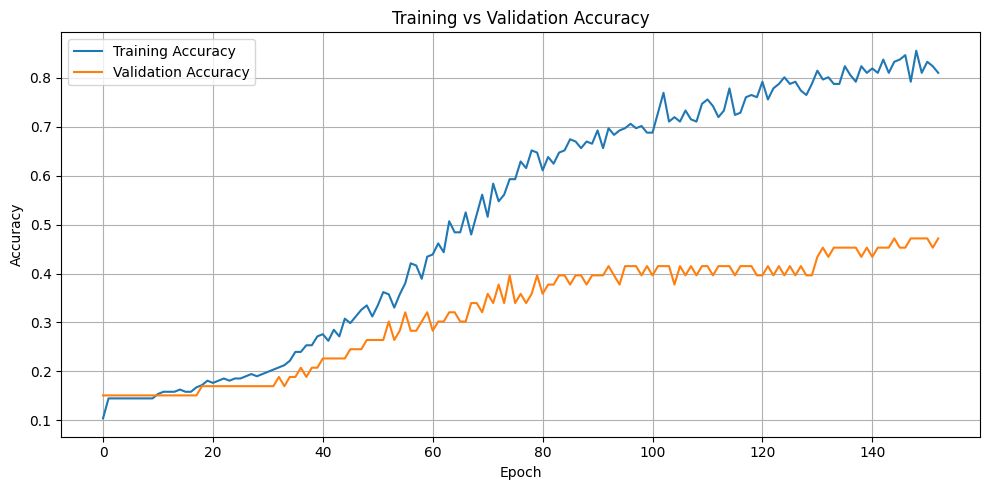

In [ ]:

# ==========================================
# 8. PLOT ACCURACY CURVES
# ==========================================

import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))

plt.plot(
    history.history["accuracy"],
    label="Training Accuracy"
)

plt.plot(
    history.history["val_accuracy"],
    label="Validation Accuracy"
)

plt.title("Training vs Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")

plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()


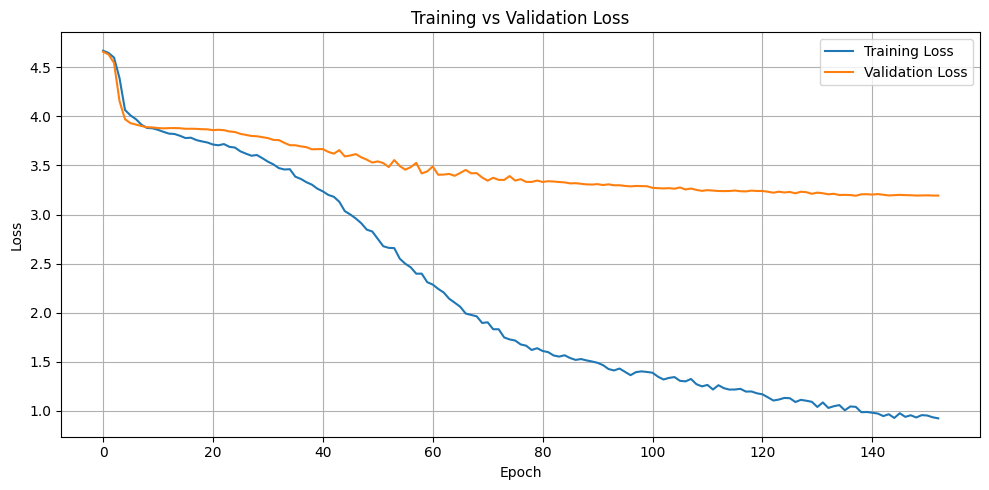

In [ ]:

# ==========================================
# 9. PLOT LOSS CURVES
# ==========================================

plt.figure(figsize=(10, 5))

plt.plot(
    history.history["loss"],
    label="Training Loss"
)

plt.plot(
    history.history["val_loss"],
    label="Validation Loss"
)

plt.title("Training vs Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")

plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()


In [ ]:
#representation
# 1.1 Vocabulary
for word, index in tokenizer.word_index.items():
    print(f"{word}: {index}")

endtoken: 1
the: 2
learning: 3
data: 4
a: 5
model: 6
training: 7
from: 8
machine: 9
is: 10
of: 11
to: 12
neural: 13
network: 14
weights: 15
learn: 16
patterns: 17
networks: 18
uses: 19
predictions: 20
loss: 21
language: 22
artificial: 23
learns: 24
deep: 25
type: 26
an: 27
updates: 28
during: 29
prediction: 30
intelligence: 31
computers: 32
learned: 33
make: 34
makes: 35
its: 36
through: 37
supervised: 38
neurons: 39
information: 40
process: 41
optimizer: 42
measures: 43
error: 44
gradients: 45
recurrent: 46
lstm: 47
can: 48
next: 49
word: 50
branch: 51
enables: 52
perform: 53
intelligent: 54
tasks: 55
allows: 56
foundation: 57
helps: 58
using: 59
knowledge: 60
algorithms: 61
improve: 62
experience: 63
labeled: 64
unsupervised: 65
discovers: 66
in: 67
reinforcement: 68
rewards: 69
contains: 70
interconnected: 71
each: 72
neuron: 73
receives: 74
other: 75
adjusts: 76
tries: 77
minimize: 78
backpropagation: 79
calculates: 80
help: 81
update: 82
activation: 83
function: 84
introduces: 85


In [ ]:
#Dataset after self-supervised learning
# 1.2 Dataset after self-supervised learning
for i in range(10):
    input_words = tokenizer.sequences_to_texts([X_train[i]])[0]
    target_word = tokenizer.index_word.get(y_train[i], "[UNKNOWN]")

    print(f"X: {input_words}")
    print(f"y: {target_word}")
    print("-" * 40)

X: machine
y: learning
----------------------------------------
X: machine learning
y: is
----------------------------------------
X: machine learning is
y: a
----------------------------------------
X: machine learning is a
y: branch
----------------------------------------
X: machine learning is a branch
y: of
----------------------------------------
X: machine learning is a branch of
y: artificial
----------------------------------------
X: machine learning is a branch of artificial
y: intelligence
----------------------------------------
X: machine learning is a branch of artificial intelligence
y: endtoken
----------------------------------------
X: artificial
y: intelligence
----------------------------------------
X: artificial intelligence
y: enables
----------------------------------------
